$\LARGE{EN3160\ Assignment\ 3}\\\LARGE{Neural\ Networks}$

$\large{Index:\ 230544C}\\
\large{Name:\ Rathnayake\ M.\ A.\ G.\ K.\ N.}$

[GitHub folder](https://github.com/codingNR29/Image-processing/tree/main/Assignments/Assignment%202)

[GitHub repo](https://github.com/codingNR29/Image-processing.git)

In [7]:
#Adding libraries
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

$Q1)$

Files already downloaded and verified
Files already downloaded and verified
Epoch 1/20, Loss: 0.9768694026470184
Epoch 2/20, Loss: 0.9498068351745605
Epoch 3/20, Loss: 0.9360685920715333
Epoch 4/20, Loss: 0.9275151143670082
Epoch 5/20, Loss: 0.9215781893134117
Epoch 6/20, Loss: 0.9171761496663093
Epoch 7/20, Loss: 0.913764465868473
Epoch 8/20, Loss: 0.9110380571484565
Epoch 9/20, Loss: 0.9088093150854111
Epoch 10/20, Loss: 0.9069572775959969
Epoch 11/20, Loss: 0.9053974495530128
Epoch 12/20, Loss: 0.9040703973770141
Epoch 13/20, Loss: 0.9029319686889649
Epoch 14/20, Loss: 0.9019489486813546
Epoch 15/20, Loss: 0.9010952159166336
Epoch 16/20, Loss: 0.9003503997921943
Epoch 17/20, Loss: 0.8996979324221611
Epoch 18/20, Loss: 0.899124560713768
Epoch 19/20, Loss: 0.8986193851232529
Epoch 20/20, Loss: 0.8981729745268822


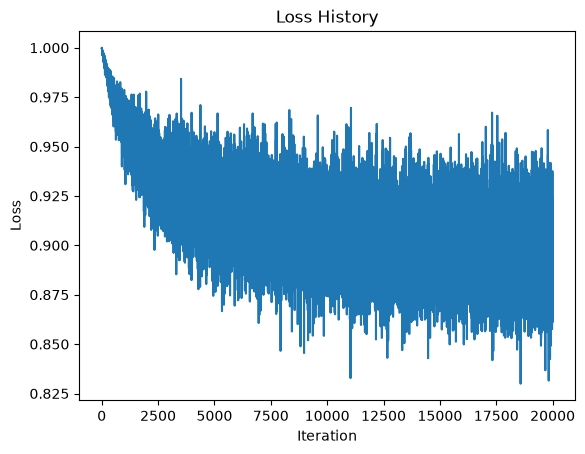

Training accuracy: 32.20%
Test accuracy: 32.43%


In [6]:
# 1. Dataloading
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

batch_size = 50

trainset = torchvision.datasets.CIFAR10(
    root='./data', train=True, download=True, transform=transform
)
trainloader = torch.utils.data.DataLoader(
    trainset, batch_size=batch_size, shuffle=True, num_workers=2
)

testset = torchvision.datasets.CIFAR10(
    root='./data', train=False, download=True, transform=transform
)
testloader = torch.utils.data.DataLoader(
    testset, batch_size=batch_size, shuffle=False, num_workers=2
)

classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')


# 2. Define Network Parameters
Din = 3 * 32 * 32  # Input size (flattened CIFAR-10 image size)
K = 10             # Output size (number of classes in CIFAR-10)
std = 1e-5

# Initialize weights and biases
w = torch.randn(Din, K) * std  # One layer: directly map input to output
b = torch.zeros(K)

# Hyperparameters
iterations = 20
lr = 2e-6          # Learning rate
lr_decay = 0.9     # Learning rate decay
reg = 0            # Regularization
loss_history = []


# 3. Training Loop
for t in range(iterations):
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        # Get inputs and labels
        inputs, labels = data
        Ntr = inputs.shape[0]                                      # Batch size
        x_train = inputs.view(Ntr, -1)                             # Flatten input to (Ntr, Din)
        y_train_onehot = nn.functional.one_hot(labels, K).float()  # Convert labels to one-hot

        # Forward pass
        y_pred = x_train.mm(w) + b                                 # Output layer activation

        # Loss calculation (Mean Squared Error with regularization)
        loss = (1 / Ntr) * torch.sum((y_pred - y_train_onehot) ** 2) + reg * torch.sum(w ** 2)
        loss_history.append(loss.item())
        running_loss += loss.item()

        # Backpropagation
        dy_pred = (2.0 / Ntr) * (y_pred - y_train_onehot)
        dw = x_train.t().mm(dy_pred) + reg * w
        db = dy_pred.sum(dim=0)

        # Parameter update
        w -= lr * dw
        b -= lr * db

    # Print loss for every epoch
    if t % 1 == 0:
        print(f"Epoch {t + 1}/{iterations}, Loss: {running_loss / len(trainloader)}")

    # Learning rate decay
    lr *= lr_decay


# 4. Plotting the Loss History
plt.plot(loss_history)
plt.title("Loss History")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()


# 5. Calculate Accuracy on Training Set
correct_train = 0
total_train = 0

with torch.no_grad():
    for data in trainloader:
        inputs, labels = data
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)
        y_train_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        y_train_pred = x_train.mm(w) + b
        predicted_train = torch.argmax(y_train_pred, dim=1)
        total_train += labels.size(0)
        correct_train += (predicted_train == labels).sum().item()

train_acc = 100 * correct_train / total_train
print(f"Training accuracy: {train_acc:.2f}%")


# 6. Calculate Accuracy on Test Set
correct_test = 0
total_test = 0

with torch.no_grad():
    for data in testloader:
        inputs, labels = data
        Nte = inputs.shape[0]
        x_test = inputs.view(Nte, -1)
        y_test_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        y_test_pred = x_test.mm(w) + b
        predicted_test = torch.argmax(y_test_pred, dim=1)
        total_test += labels.size(0)
        correct_test += (predicted_test == labels).sum().item()

test_acc = 100 * correct_test / total_test
print(f"Test accuracy: {test_acc:.2f}%")

$a)$

In [9]:
#Selecting device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

torch.manual_seed(42)

#New network parameters
Din = 3 * 32 * 32
H = 100
K = 10

#Defining layer weights

#Layer 1
W1 = torch.randn(Din, H, device=device) / (Din ** 0.5)
b1 = torch.zeros(H, device=device)

#Layer 2
W2 = torch.randn(H, K, device=device) / (H ** 0.5)
b2 = torch.zeros(K, device=device)

lr = 0.1
epochs = 10

epoch_losses = []


Using: cuda


$b)$

In [10]:
#Training
for epoch in range(epochs):
    total_loss = 0.0
    total_samples = 0

    for images, labels in trainloader:
        images = images.to(device)
        labels = labels.to(device)

        N = images.shape[0]
        X = images.reshape(N, -1)

        # Forward propagation
        Z1 = X @ W1 + b1
        A1 = torch.sigmoid(Z1)
        Z2 = A1 @ W2 + b2

        # Stable softmax and cross-entropy
        log_probs = Z2 - torch.logsumexp(
            Z2, dim=1, keepdim=True
        )
        loss = -log_probs[
            torch.arange(N, device=device), labels
        ].mean()

        # Manual backward propagation
        dZ2 = torch.exp(log_probs)
        dZ2[torch.arange(N, device=device), labels] -= 1
        dZ2 /= N

        dW2 = A1.T @ dZ2
        db2 = dZ2.sum(dim=0)

        dZ1 = (dZ2 @ W2.T) * A1 * (1 - A1)

        dW1 = X.T @ dZ1
        db1 = dZ1.sum(dim=0)

        # Gradient descent
        W1 -= lr * dW1
        b1 -= lr * db1
        W2 -= lr * dW2
        b2 -= lr * db2

        total_loss += loss.item() * N
        total_samples += N

    avg_loss = total_loss / total_samples
    epoch_losses.append(avg_loss)

    print(f"Epoch {epoch+1}/{epochs} | Loss: {avg_loss:.4f}")


Epoch 1/10 | Loss: 1.8062
Epoch 2/10 | Loss: 1.6788
Epoch 3/10 | Loss: 1.6180
Epoch 4/10 | Loss: 1.5704
Epoch 5/10 | Loss: 1.5255
Epoch 6/10 | Loss: 1.4839
Epoch 7/10 | Loss: 1.4487
Epoch 8/10 | Loss: 1.4144
Epoch 9/10 | Loss: 1.3819
Epoch 10/10 | Loss: 1.3534


$c)$

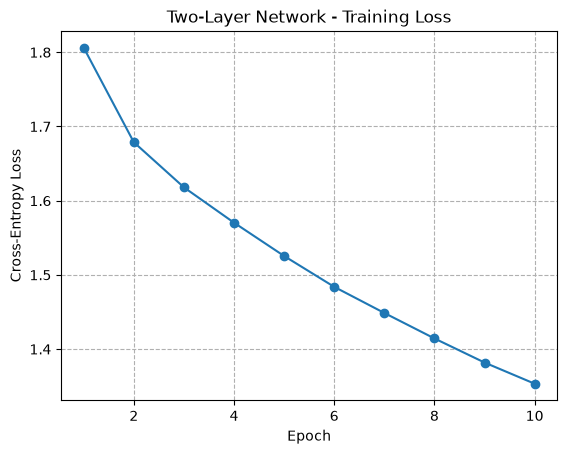

Training accuracy: 55.58%
Test accuracy: 48.04%


In [12]:
#Visualization
plt.plot(range(1, epochs + 1), epoch_losses, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Two-Layer Network - Training Loss")
plt.grid(True, linestyle = "--")
plt.show()

def calculate_accuracy(loader):
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            X = images.to(device).reshape(images.shape[0], -1)
            labels = labels.to(device)

            A1 = torch.sigmoid(X @ W1 + b1)
            logits = A1 @ W2 + b2

            predicted = torch.argmax(logits, dim=1)

            correct += (predicted == labels).sum().item()
            total += labels.size(0)

    return 100 * correct / total

train_acc = calculate_accuracy(trainloader)
test_acc = calculate_accuracy(testloader)

print(f"Training accuracy: {train_acc:.2f}%")
print(f"Test accuracy: {test_acc:.2f}%")


### Q1: Results and Discussion

A two-layer fully connected neural network was implemented for CIFAR-10 image classification by extending the provided single-layer network. A hidden layer consisting of 100 neurons with sigmoid activation was introduced, and the original mean squared error objective was replaced with softmax cross-entropy loss. Forward propagation and backpropagation were implemented manually using matrix operations and the chain rule.

The network was trained for 10 epochs using mini-batch gradient descent. The training loss decreased consistently from approximately 1.81 to 1.35, indicating that the network was successfully learning from the training data.

The final training accuracy was **55.58%**, while the test accuracy was **48.04%**. The difference of 7.54 percentage points suggests a generalization gap between training and unseen data. Although the network performed substantially better than random classification, its performance was limited by the use of flattened pixel values rather than spatial feature extraction.

The experiment demonstrates how nonlinear activations, cross-entropy loss, and backpropagation enable a multilayer network to learn image classification. It also motivates the use of convolutional neural networks, which can better exploit spatial relationships within images.

$Q2)$